### First let's load needed packages

In [42]:
import pyrecon
import pandas as pd


from pyrecon.stepwise import find_best_set_of_chrons,observed_vs_stepwise_regression,stepwise_regression_reconstruction
from pyrecon.pca import find_best_set_of_PCA,observed_vs_pca_regression,pca_regression_reconstruction
from pyrecon.plotting import plot_observed_vs_reconstructed,plot_full_reconstruction

### Let's upload chronologies and observed values as dataframes

In [22]:
# 1) Load the chronologies as a DataFrame (year-indexed)

df = pd.read_excel('Data/chrons.xlsx', header=0, index_col=0)

# 2) Load the observed gauge values as a DataFrame

nf = pd.read_excel('Data/guage data.xlsx', header=2, index_col=0)
nf = nf.iloc[:, [0]]

# 3) Join on the shared years to build the calibration X and y

data = df.join(nf, how='inner').dropna()
X_calib = data[df.columns]
y_calib = data[nf.columns[0]]

#  Stepwise Regression

## 1) First we need to choose the best set of chronologies using stepwise selection


=== Best subset (sequential selection) ===
Direction: forward
Number of chrons : 8
Best chrons: ['DJM', 'DOU', 'PUM', 'RED', 'RIF', 'SAR', 'TRG', 'WIL']
CV neg-MSE: -6729104.0333 ± 1884005.2328


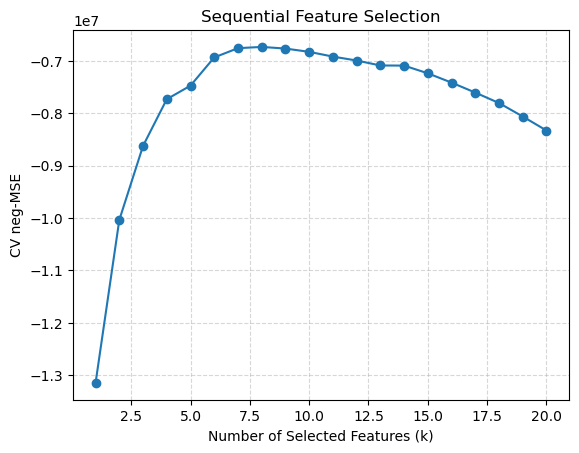

In [12]:
number_of_chrons, best_chrons, best_score, best_std, results = find_best_set_of_chrons(
    X_calib, y_calib, 20, direction="forward", plot=True)

## 2) Then we fit the model to the best-selected chronologies and plot.

In-sample R² : 0.8124
Cross-validated R² : 0.7373 ± 0.0980


<AxesSubplot:title={'center':'Observed vs Stepwise_Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (MAF)'>

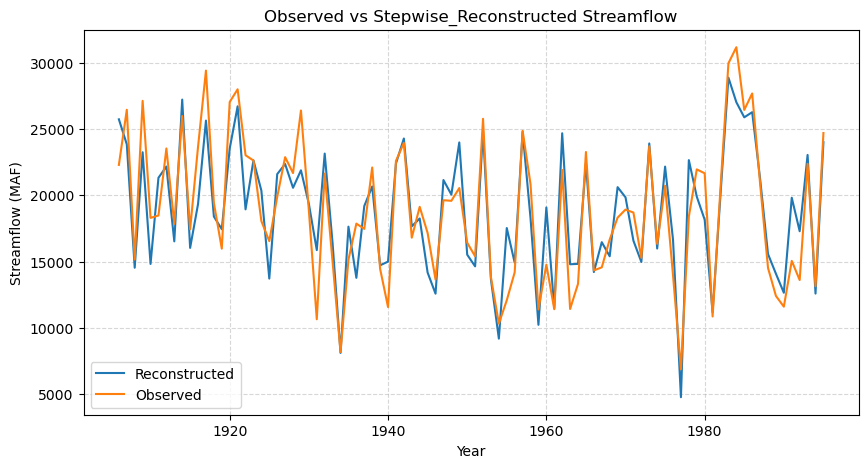

In [52]:
X_best = X_calib[best_chrons]
pipe, recon, r2_in, cv_scores= observed_vs_stepwise_regression(X_best, y_calib)
plot_observed_vs_reconstructed(X_calib.index, recon, y_calib, ylabel='Streamflow (MAF)',
                               xlabel='Year',title ='Observed vs Stepwise_Reconstructed Streamflow')

## 3) Then we apply the selected chronologies over the full period and run the reconstruction.

<AxesSubplot:title={'center':'Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (MAF)'>

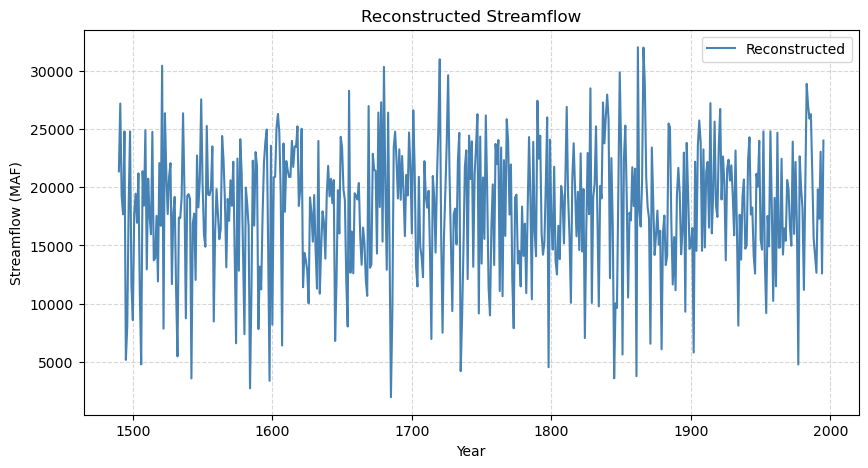

In [17]:
X_paleo = df[best_chrons]
full_recon =stepwise_regression_reconstruction(X_paleo, pipe)
plot_full_reconstruction(df.index, full_recon, ylabel='Streamflow (MAF)',xlabel='Year',
                         title ='Reconstructed Streamflow')

# PCA Regression

## 1) First we need to choose the best set of PCAs

In [43]:
df = pd.read_excel('Data/chrons.xlsx', header=0, index_col=0)


nf = pd.read_excel('Data/guage data.xlsx', header=2, index_col=0)
nf = nf.iloc[:, 0]

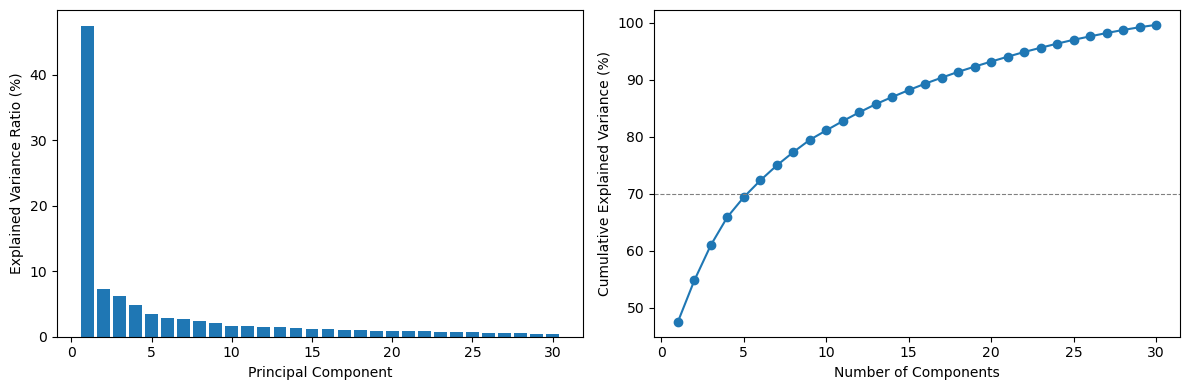

In [47]:
scaler, pca, scores, loadings, variance, cum_var, fig, axes=find_best_set_of_PCA(df, 30, 1490, 1995, 
                                                                                 70, plot =True)

In-sample R² (first 1 PCs): 0.7207
Cross-validated R² (first 1 PCs): 0.6824 ± 0.1116


<AxesSubplot:title={'center':'Observed vs PCA_Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (MAF)'>

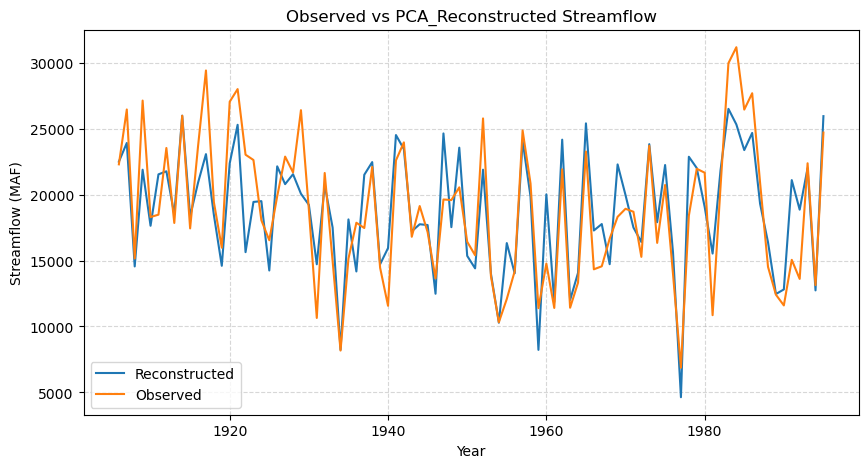

In [54]:
pipe, recon, r2_in, cv_scores = observed_vs_pca_regression(scores, nf, 1, 1906, 1995)
plot_observed_vs_reconstructed(X_calib.index, recon, y_calib, ylabel='Streamflow (MAF)',
                               xlabel='Year',title ='Observed vs PCA_Reconstructed Streamflow')

<AxesSubplot:title={'center':'Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (MAF)'>

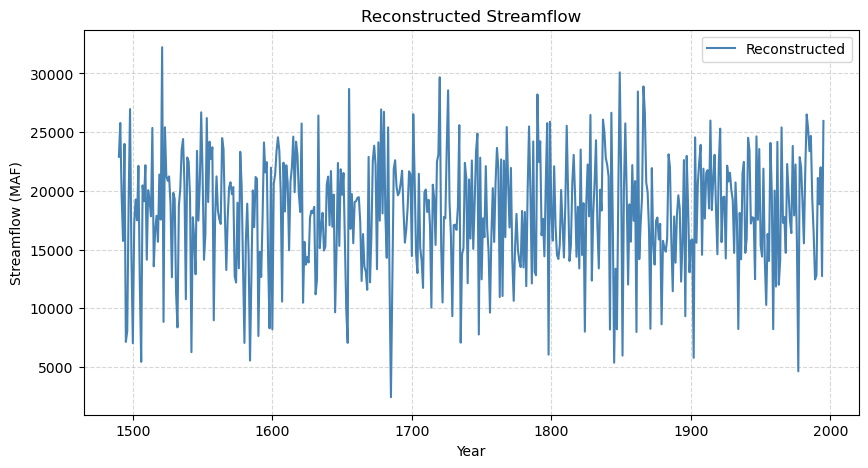

In [56]:
full_recon = pca_regression_reconstruction(scores, 1, 1490, 1995, pipe)
plot_full_reconstruction(df.index, full_recon, ylabel='Streamflow (MAF)',xlabel='Year',
                         title ='Reconstructed Streamflow')